### Pearson vs. Spearman Correlation Analysis in Python

### 1.  Dataset
- Core Focus
    * Fundamental concepts of correlation, Pearson correlation, and Spearman's rank correlation.
- Dataset Used
    * The Palmer Penguins dataset collected by Dr. Kristen Gorman.
    * Sample Size: 344 total observations, resulting in 333 complete observations after dropping missing values.
    * Continuous Variables: Bill length (mm), bill depth (mm), flipper length (mm), and body mass (g).
    * Categorical / Non-Continuous Variables: Penguin species (Adelie, Chinstrap, Gentoo), island (Torgersen, Biscoe, Dream), and sex (male, female).

### 2. Core Concepts of Correlation
- Definition
    * Measures the strength and direction of a relationship between two variables.
- Properties
    * Range: Values range strictly from -1.0 to +1.0.
    * Direction: Positive correlation means both variables increase together; negative (inverse) correlation means one variable increases as the other decreases.
- Scale Interpretation
    * $+1.0$: Perfect positive correlation.
    * $0.0$: No linear correlation.
    * $-1.0$: Perfect negative correlation.
- Golden Rule
    * Correlation does not imply causation.

### 3. Pearson Correlation vs. Spearman Rank Correlation

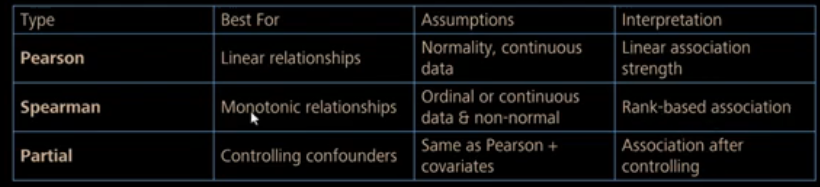

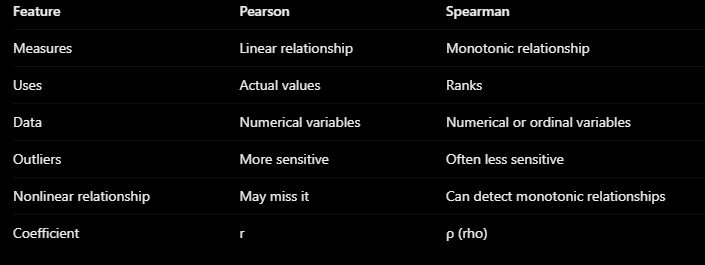



#### Pearson Correlation Coefficient ($r$)
- Purpose
    * Measures the strength and direction of a linear relationship between two continuous variables.
- Mathematical Formula
    $$r = \frac{\sum (X - \bar{X})(Y - \bar{Y})}{\sqrt{\sum (X - \bar{X})^2 \sum (Y - \bar{Y})^2}}$$
    * Where $\bar{X}$ and $\bar{Y}$ represent the sample means of variables $X$ and $Y$.
- Core Assumptions
    1. Continuous Data: Both variables must be continuous numerical measurements.
    2. Linearity: The underlying relationship between variables must be linear.
    3. Bivariate Normality: Both variables must be normally distributed.
    4. Homoscedasticity: The variance of the residuals must remain constant across all fitted values.
    5. Independence of Observations: Each pair of data points must be independent.
    6. No Extreme Outliers: Outliers can disproportionately distort the correlation coefficient.

#### Spearman Rank Correlation Coefficient ($\rho$ or Row)
- Purpose
    * Measures the strength and direction of a monotonic relationship (whether variables move in the same relative direction, even if non-linearly).
- When to Use
    * Used when Pearson assumptions fail—specifically for non-normal continuous data, ordinal data, non-linear relationships, or datasets containing outliers.
- Mechanism
    * Converts raw data values into numerical ranks (1st, 2nd, 3rd place) and computes the correlation on the assigned ranks.
- Handling Ties
    * Automatically handles tied values by assigning the average rank (e.g., two tied values for 2nd place both receive a rank of 2.5).

### 4. Diagnostic Tests & Checking Assumptions in Python

- Normality Testing
    * Method: Evaluated using the Shapiro-Wilk test (`scipy.stats.shapiro`) alongside visual inspection via histograms, Q-Q plots, and box plots.
    * Hypothesis Decision:
        - Null Hypothesis ($H_0$): The dataset is normally distributed.
        - If $p < 0.05$, $H_0$ is disproved, confirming the data is non-normal.
    * Palmer Penguins Outcome: All four continuous variables yielded $p < 0.05$ in formal Shapiro-Wilk testing, indicating non-normality; however, visual Q-Q and histogram plots showed bill length, flipper length, and body mass were near-normal, while bill depth exhibited a bimodal profile.

- Linearity Testing
    * Method: Fits both a 1st-degree polynomial (linear) and a 2nd-degree polynomial (quadratic) regression model to the data.
    * Evaluation Metric: Computes the improvement in $R^2$ ($R^2_{\text{quadratic}} - R^2_{\text{linear}}$).
    * Threshold: If the $R^2$ improvement is $< 0.05$ (5%), the additional quadratic term offers negligible benefit, satisfying the linearity assumption.

- Homoscedasticity Testing (Simplified Breusch-Pagan Check)
    * Method: Fits a linear model, extracts absolute residuals ($|Y - Y_{\text{fitted}}|$), and performs a Pearson test between the absolute residuals and the fitted values.
    * Threshold: A $p$-value $> 0.05$ indicates no significant correlation between residuals and fitted values, confirming equal variance (homoscedasticity).

- Outlier Detection
    * Univariate Outliers: Identified via $Z$-scores (values beyond $\pm 3\sigma$ from the mean) or interquartile ranges.
    * Bivariate Outliers: Evaluated using Mahalanobis Distance, which measures how far a 2D data point lies from the dataset center using the covariance matrix. Points exceeding the Chi-Square ($\chi^2$) critical value at a 99.9% confidence level are flagged as bivariate outliers.

### 5. Python Implementation & Comparative Results

- Primary Python Functions
    * Pandas Built-in: `df.corr(method='pearson')` and `df.corr(method='spearman')` generate complete correlation matrices.
    * SciPy Functions: `scipy.stats.pearsonr(x, y)` and `scipy.stats.spearmanr(x, y)` return both the correlation coefficient ($r$ or $\rho$) and the corresponding two-tailed $p$-value.

- Key Results on Palmer Penguins Data
    * Flipper Length vs. Body Mass:
        - Pearson $r \approx 0.589$.
        - Spearman $\rho \approx 0.576$.
    * Pearson vs. Spearman Agreement: Plotting Pearson coefficients against Spearman coefficients across all feature pairs produces a near-straight diagonal line, proving that minor deviations from normality do not prevent Pearson from agreeing closely with Spearman.
    * Confounding Variable Preview: Splitting data by species reveals distinct clusters (e.g., bill length and depth vary significantly across Adelie, Chinstrap, and Gentoo), highlighting the need for partial correlation to control for species as a confounder in subsequent analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr, spearmanr, kendalltau
import statsmodels.api as sm
from statsmodels.stats.correlation_tools import corr_nearest, corr_clipped
import warnings
from itertools import combinations
import requests
from io import StringIO

from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.linear_model import LinearRegression


from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import squareform
from statsmodels.stats.multitest import multipletests
from sklearn.utils import resample
import math

In [2]:
# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# Set visualization style consistent with previous tutorials
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

In [3]:
# Load palmer penguin dataset from online source
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"

penguins = pd.read_csv(url)


# Display basic information about the dataset
print("\nDataset Information:")
print("=" * 25)
print(f"Shape: {penguins.shape}")
print(f"Columns: {list(penguins.columns)}")


Dataset Information:
Shape: (344, 7)
Columns: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


In [4]:

# Check for missing values
print("\nMissing values per column:")
missing_counts = penguins.isnull().sum()
for col, count in missing_counts.items():
    print(f"  {col}: {count}")

# Remove rows with missing values for correlation analysis
penguins_clean = penguins.dropna()
print(f"\nAfter removing missing values: {penguins_clean.shape[0]} complete observations")


Missing values per column:
  species: 0
  island: 0
  bill_length_mm: 2
  bill_depth_mm: 2
  flipper_length_mm: 2
  body_mass_g: 2
  sex: 11

After removing missing values: 333 complete observations


In [5]:
# Define continuous variables for correlation analysis
continuous_vars = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
categorical_vars = ['species', 'island', 'sex']

### 1. Introduction to correlation analysis

#### * The Coefficient of Variation (CV) tells us how much variation there is in a variable compared with its own average (mean).
* $CV = (standard Deviation / mean ) * 100$
* less variation - closer to avg , data is more consistent.
* more variation - more spread form avg , data is less consistent.


EXPLORATORY DATA ANALYSIS FOR CORRELATION

Descriptive Statistics for Continuous Variables:
--------------------------------------------------
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          333.00         333.00             333.00       333.00
mean            43.99          17.16             200.97      4207.06
std              5.47           1.97              14.02       805.22
min             32.10          13.10             172.00      2700.00
25%             39.50          15.60             190.00      3550.00
50%             44.50          17.30             197.00      4050.00
75%             48.60          18.70             213.00      4775.00
max             59.60          21.50             231.00      6300.00

Coefficient of Variation (CV = std/mean):
----------------------------------------
bill_length_mm      :   12.4%
bill_depth_mm       :   11.5%
flipper_length_mm   :    7.0%
body_mass_g         :   19.1%

Normality Assessment (Shapiro-

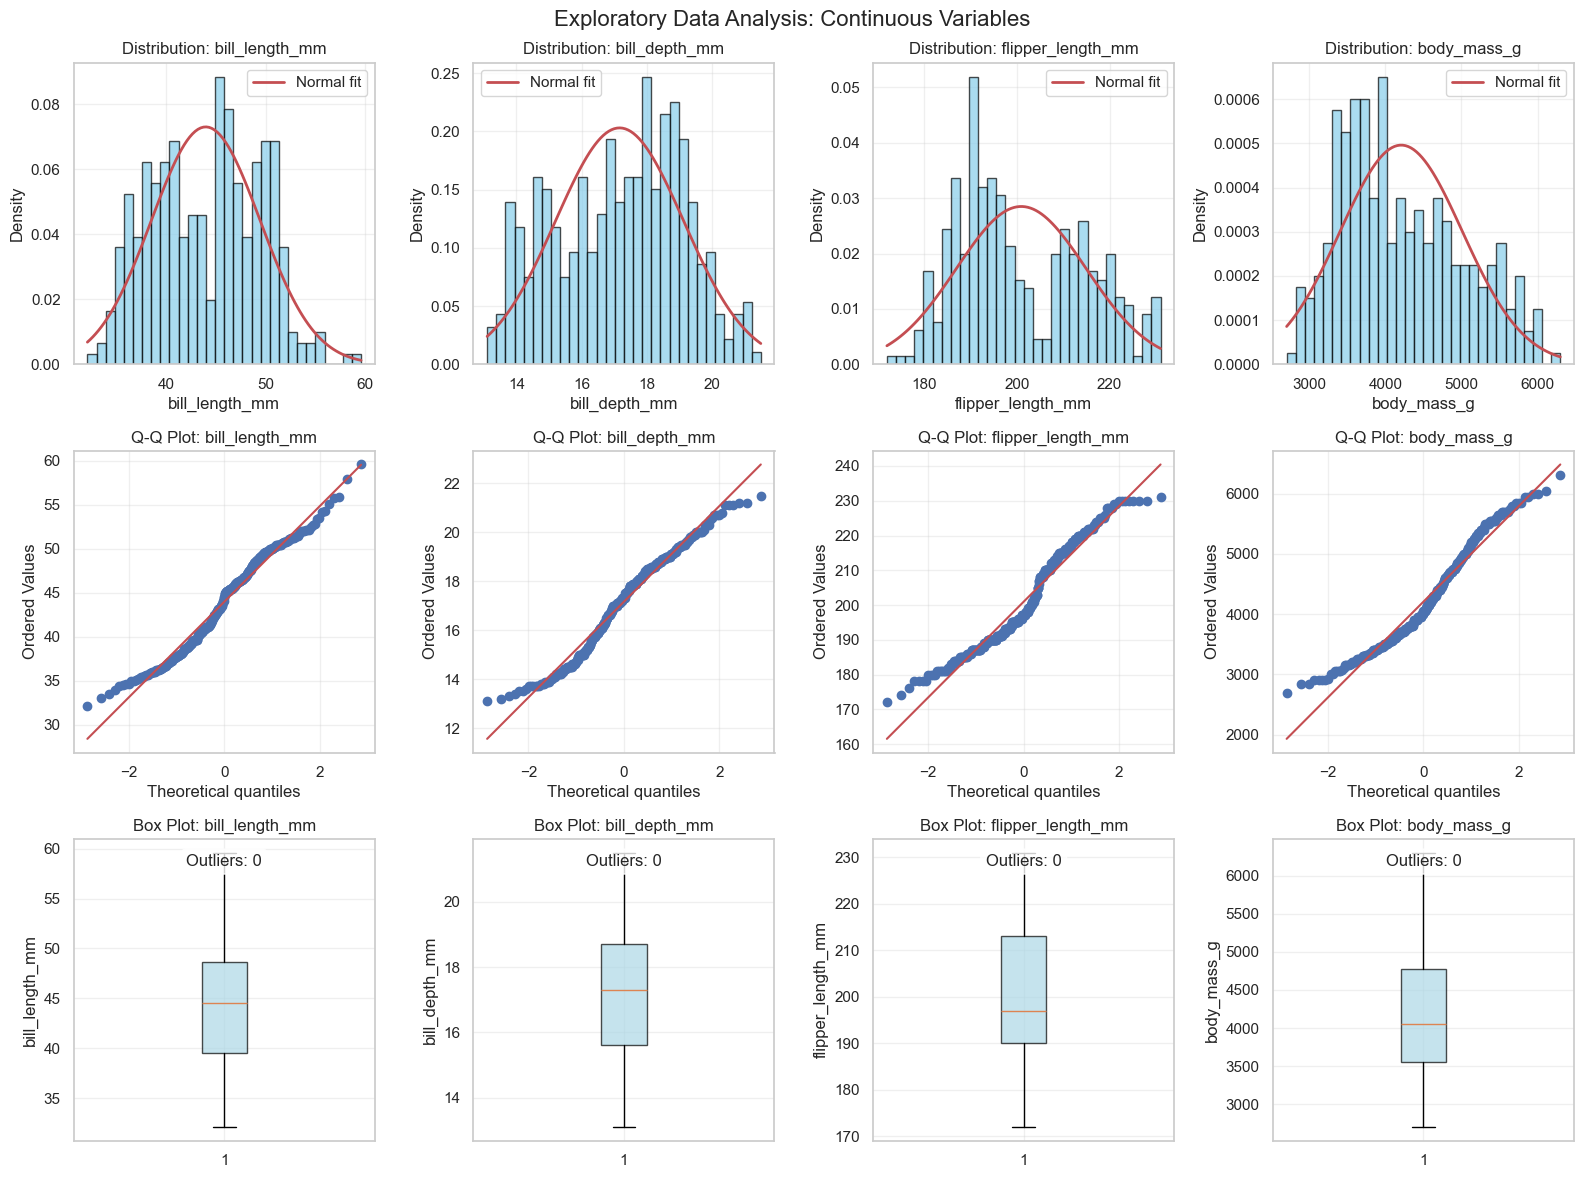


Outlier Analysis:
--------------------
bill_length_mm      :   0 outliers (  0.0%)
bill_depth_mm       :   0 outliers (  0.0%)
flipper_length_mm   :   0 outliers (  0.0%)
body_mass_g         :   0 outliers (  0.0%)

Species-specific Means:
-------------------------
           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
species                                                                 
Adelie              38.82          18.35             190.10      3706.16
Chinstrap           48.83          18.42             195.82      3733.09
Gentoo              47.57          15.00             217.24      5092.44


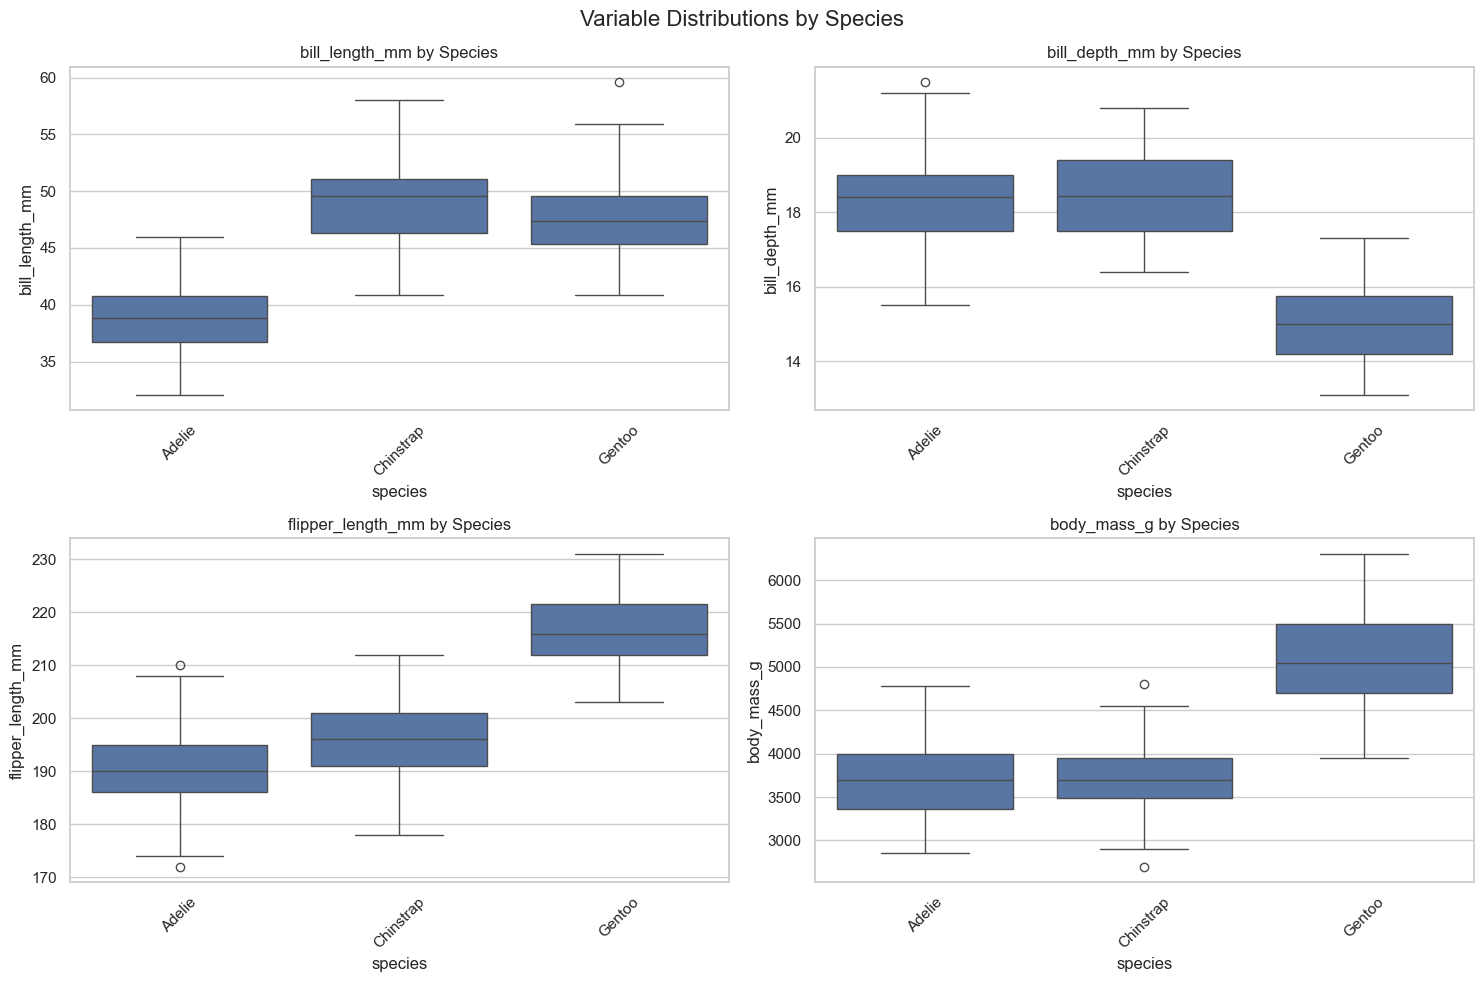

In [6]:
def explore_correlation_data(data, continuous_vars):
    """
    Exploration of the dataset focusing on relationships between continuous variables.

    """
    print("\n" + "=" * 70)
    print("EXPLORATORY DATA ANALYSIS FOR CORRELATION")
    print("=" * 70)

    # Basic descriptive statistics
    print("\nDescriptive Statistics for Continuous Variables:")
    print("-" * 50)

    desc_stats = data[continuous_vars].describe().round(2)
    print(desc_stats)

    # Calculate coefficient of variation for each variable
    # Remember that CV helps to understand the extent of dispersion or variability around the mean of a dataset.
    print(f"\nCoefficient of Variation (CV = std/mean):")
    print("-" * 40)
    for var in continuous_vars:
        mean_val = data[var].mean()
        std_val = data[var].std()
        cv = (std_val / mean_val) * 100
        print(f"{var:<20}: {cv:>6.1f}%")

    # Check distributions for normality (important for Pearson correlation)
    print(f"\nNormality Assessment (Shapiro-Wilk Test):")
    print("-" * 45)
    normality_results = {}

    for var in continuous_vars:
        # Use sample if data is too large for Shapiro-Wilk
        sample_data = data[var].dropna()
        if len(sample_data) > 5000:
            sample_data = sample_data.sample(5000, random_state=42)

        stat, p_value = stats.shapiro(sample_data)
        normality_results[var] = {'statistic': stat, 'p_value': p_value}

        interpretation = "Normal" if p_value > 0.05 else "Non-normal"
        print(f"{var:<20}: W = {stat:.4f}, p = {p_value:.4f} ({interpretation})")

    # Create different visualizations
    n_vars = len(continuous_vars)
    fig, axes = plt.subplots(3, n_vars, figsize=(4*n_vars, 12))
    fig.suptitle('Exploratory Data Analysis: Continuous Variables', fontsize=16)

    for i, var in enumerate(continuous_vars):
        var_data = data[var].dropna()

        # Row 1: Histograms with normal overlay
        axes[0, i].hist(var_data, bins=30, density=True, alpha=0.7,
                       color='skyblue', edgecolor='black')

        # Overlay normal distribution
        mu, sigma = stats.norm.fit(var_data)
        x = np.linspace(var_data.min(), var_data.max(), 100)
        axes[0, i].plot(x, stats.norm.pdf(x, mu, sigma), 'r-',
                       linewidth=2, label='Normal fit')

        axes[0, i].set_title(f'Distribution: {var}')
        axes[0, i].set_xlabel(var)
        axes[0, i].set_ylabel('Density')
        axes[0, i].legend()
        axes[0, i].grid(True, alpha=0.3)

        # Row 2: Q-Q plots for normality
        stats.probplot(var_data, dist="norm", plot=axes[1, i])
        axes[1, i].set_title(f'Q-Q Plot: {var}')
        axes[1, i].grid(True, alpha=0.3)

        # Row 3: Box plots
        axes[2, i].boxplot(var_data, patch_artist=True,
                          boxprops=dict(facecolor='lightblue', alpha=0.7))
        axes[2, i].set_title(f'Box Plot: {var}')
        axes[2, i].set_ylabel(var)
        axes[2, i].grid(True, alpha=0.3)

        # Add outlier information
        Q1 = var_data.quantile(0.25)
        Q3 = var_data.quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        outliers = var_data[(var_data < lower_bound) | (var_data > upper_bound)]

        axes[2, i].text(0.5, 0.95, f'Outliers: {len(outliers)}',
                       transform=axes[2, i].transAxes, ha='center', va='top',
                       bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    plt.tight_layout()
    plt.show()

    # Identify potential outliers
    print(f"\nOutlier Analysis:")
    print("-" * 20)

    outlier_summary = {}
    for var in continuous_vars:
        var_data = data[var].dropna()
        Q1 = var_data.quantile(0.25)
        Q3 = var_data.quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = var_data[(var_data < lower_bound) | (var_data > upper_bound)]
        outlier_percentage = (len(outliers) / len(var_data)) * 100

        outlier_summary[var] = {
            'count': len(outliers),
            'percentage': outlier_percentage,
            'lower_bound': lower_bound,
            'upper_bound': upper_bound
        }

        print(f"{var:<20}: {len(outliers):>3} outliers ({outlier_percentage:>5.1f}%)")

    # Species-specific analysis
    if 'species' in data.columns:
        print(f"\nSpecies-specific Means:")
        print("-" * 25)
        species_means = data.groupby('species')[continuous_vars].mean().round(2)
        print(species_means)

        # Visualize species differences
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))
        fig.suptitle('Variable Distributions by Species', fontsize=16)

        for i, var in enumerate(continuous_vars):
            row = i // 2
            col = i % 2

            sns.boxplot(data=data, x='species', y=var, ax=axes[row, col])
            axes[row, col].set_title(f'{var} by Species')
            axes[row, col].tick_params(axis='x', rotation=45)

        plt.tight_layout()
        plt.show()

    return {
        'descriptive_stats': desc_stats,
        'normality_results': normality_results,
        'outlier_summary': outlier_summary,
        'species_means': species_means if 'species' in data.columns else None
    }

# Step 1: Explore the data
exploration_results = explore_correlation_data(penguins_clean, continuous_vars)
     

### Correlation concepts- visual demonstration


CORRELATION CONCEPTS: VISUAL DEMONSTRATION


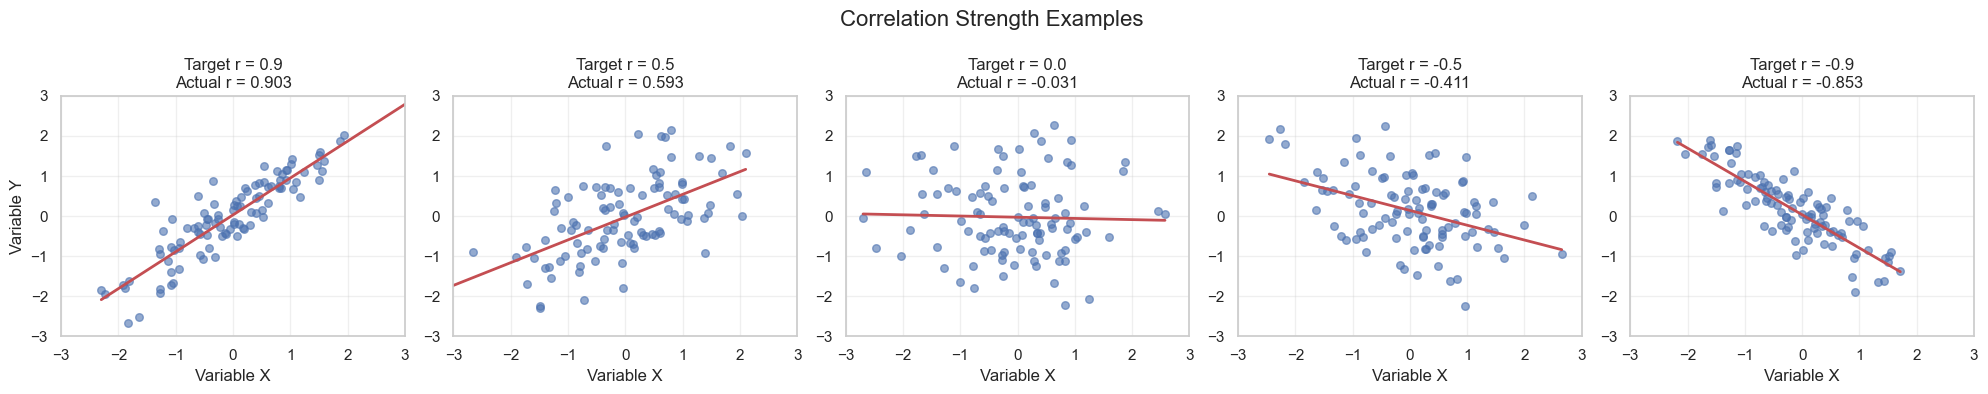


Correlation Interpretation Guide:
-----------------------------------
Perfect positive (r = +1.0)   : Y increases exactly as X increases
Strong positive (r = +0.7 to +0.9): Y tends to increase as X increases
Moderate positive (r = +0.3 to +0.7): Y somewhat increases as X increases
Weak (r = -0.3 to +0.3)       : Little to no linear relationship
Moderate negative (r = -0.7 to -0.3): Y somewhat decreases as X increases
Strong negative (r = -0.9 to -0.7): Y tends to decrease as X increases
Perfect negative (r = -1.0)   : Y decreases exactly as X increases


In [8]:
def demonstrate_correlation_concepts():
    """
    Demonstrate correlation concepts with simulated examples to build intuition.
    We will then look at our penguin dataset
    """
    print("\n" + "=" * 70)
    print("CORRELATION CONCEPTS: VISUAL DEMONSTRATION")
    print("=" * 70)

    # Generate example data with different correlation strengths
    np.random.seed(42)
    n = 100
    x = np.random.normal(0, 1, n)

    # Create different correlation scenarios
    correlations = [0.9, 0.5, 0.0, -0.5, -0.9]
    correlation_data = {}

    for r in correlations:
        # Generate correlated data using Cholesky decomposition
        cov_matrix = np.array([[1, r], [r, 1]])
        data_pair = np.random.multivariate_normal([0, 0], cov_matrix, n)
        correlation_data[r] = {'x': data_pair[:, 0], 'y': data_pair[:, 1]}

    # Create visualization
    fig, axes = plt.subplots(1, len(correlations), figsize=(20, 4))
    fig.suptitle('Correlation Strength Examples', fontsize=16)

    for i, r in enumerate(correlations):
        x_data = correlation_data[r]['x']
        y_data = correlation_data[r]['y']
        
        # Calculate actual correlation
        actual_r, _ = pearsonr(x_data, y_data)

        # Create scatter plot
        axes[i].scatter(x_data, y_data, alpha=0.6, s=30)

        # Add regression line
        slope, intercept, _, _, _ = stats.linregress(x_data, y_data)
        line_x = np.linspace(x_data.min(), x_data.max(), 100)
        line_y = slope * line_x + intercept
        axes[i].plot(line_x, line_y, 'r-', linewidth=2)

        # Formatting
        axes[i].set_title(f'Target r = {r}\nActual r = {actual_r:.3f}')
        axes[i].set_xlabel('Variable X')
        if i == 0:
            axes[i].set_ylabel('Variable Y')
        axes[i].grid(True, alpha=0.3)
        axes[i].set_xlim(-3, 3)
        axes[i].set_ylim(-3, 3)

    plt.tight_layout()
    plt.show()

    # Interpretation guide
    print(f"\nCorrelation Interpretation Guide:")
    print("-" * 35)
    interpretation_guide = {
        "Perfect positive (r = +1.0)": "Y increases exactly as X increases",
        "Strong positive (r = +0.7 to +0.9)": "Y tends to increase as X increases",
        "Moderate positive (r = +0.3 to +0.7)": "Y somewhat increases as X increases",
        "Weak (r = -0.3 to +0.3)": "Little to no linear relationship",
        "Moderate negative (r = -0.7 to -0.3)": "Y somewhat decreases as X increases",
        "Strong negative (r = -0.9 to -0.7)": "Y tends to decrease as X increases",
        "Perfect negative (r = -1.0)": "Y decreases exactly as X increases"
    }
    for strength, description in interpretation_guide.items():
        print(f"{strength:<30}: {description}")


  # Step 2: Demonstrate correlation concepts
demonstrate_correlation_concepts()

### Basic pearson correlation analysis


BASIC PEARSON CORRELATIONS
Correlation Matrix:
--------------------
                   bill_length_mm  bill_depth_mm  flipper_length_mm  \
bill_length_mm              1.000         -0.229              0.653   
bill_depth_mm              -0.229          1.000             -0.578   
flipper_length_mm           0.653         -0.578              1.000   
body_mass_g                 0.589         -0.472              0.873   

                   body_mass_g  
bill_length_mm           0.589  
bill_depth_mm           -0.472  
flipper_length_mm        0.873  
body_mass_g              1.000  

Pairwise Correlations:
-------------------------
bill_length_mm ↔ bill_depth_mm:
  r =  -0.229, p =  0.0000, n = 333
  Weak negative correlation (significant)

bill_length_mm ↔ flipper_length_mm:
  r =   0.653, p =  0.0000, n = 333
  Moderate positive correlation (significant)

bill_length_mm ↔ body_mass_g:
  r =   0.589, p =  0.0000, n = 333
  Moderate positive correlation (significant)

bill_depth_mm ↔ f

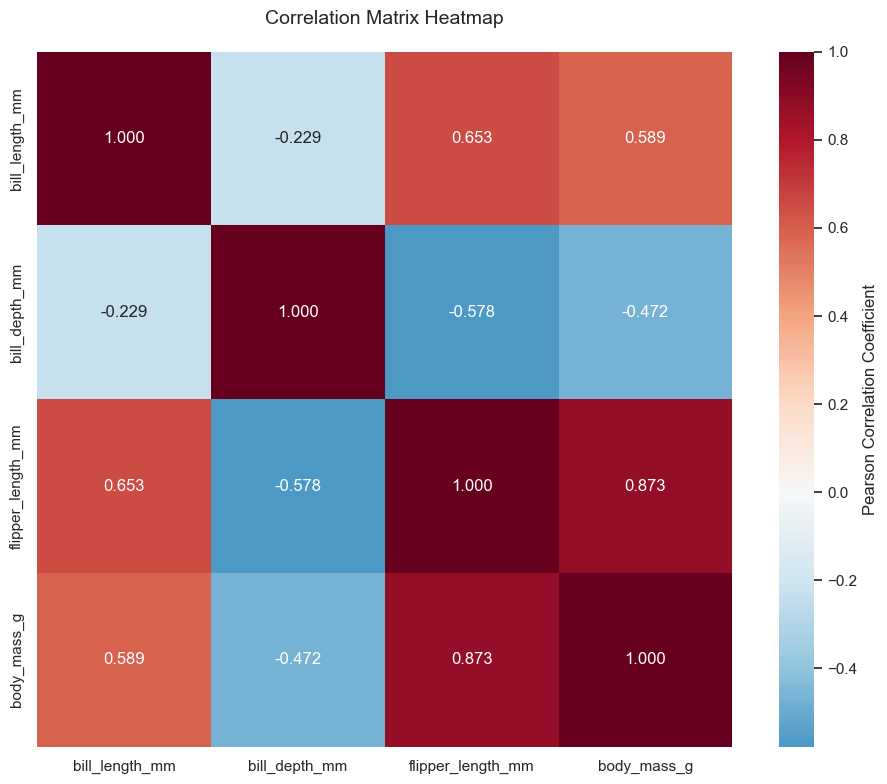

Correlation Summary:
--------------------
Number of correlations: 6
Mean |correlation|: 0.566
Max |correlation|: 0.873
Min |correlation|: 0.229

Correlations by strength:
  Weak: 1 (16.7%)
  Moderate: 4 (66.7%)
  Strong: 1 (16.7%)

Significant correlations: 6 out of 6


In [9]:
def calculate_basic_correlations(data, continuous_vars):
    """
    Calculate and interpret basic Pearson correlations between continuous variables.

    """
    print("\n" + "=" * 70)
    print("BASIC PEARSON CORRELATIONS")
    print("=" * 70)

    # Calculate correlation matrix
    corr_matrix = data[continuous_vars].corr()

    print("Correlation Matrix:")
    print("-" * 20)
    print(corr_matrix.round(3))

    # Extract unique pairs and their correlations
    print(f"\nPairwise Correlations:")
    print("-" * 25)

    correlation_results = []

    for i in range(len(continuous_vars)):
        for j in range(i+1, len(continuous_vars)):
            var1 = continuous_vars[i]
            var2 = continuous_vars[j]

            # FIXED: Calculate correlation with proper alignment
            # Get valid pairs first to ensure alignment
            valid_pairs = data[[var1, var2]].dropna()

            # Calculate correlation and significance test on aligned data
            r, p_value = pearsonr(valid_pairs[var1], valid_pairs[var2])

            # Calculate sample size
            n = len(valid_pairs)

            # Interpret strength
            if abs(r) >= 0.7:
                strength = "Strong"
            elif abs(r) >= 0.3:
                strength = "Moderate"
            else:
                strength = "Weak"

            # Interpret direction
            direction = "Positive" if r > 0 else "Negative"

            # Significance
            significance = "Significant" if p_value < 0.05 else "Not significant"

            correlation_results.append({
                'var1': var1,
                'var2': var2,
                'correlation': r,
                'p_value': p_value,
                'n': n,
                'strength': strength,
                'direction': direction,
                'significance': significance
            })

            print(f"{var1} ↔ {var2}:")
            print(f"  r = {r:>7.3f}, p = {p_value:>7.4f}, n = {n:>3}")
            print(f"  {strength} {direction.lower()} correlation ({significance.lower()})")
            print()

    # Create correlation heatmap
    plt.figure(figsize=(10, 8))

    # Create mask for upper triangle to show only lower triangle
    #mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    # Create heatmap
    sns.heatmap(corr_matrix,
                #mask=mask,
                annot=True,
                cmap='RdBu_r',
                center=0,
                square=True,
                fmt='.3f',
                cbar_kws={'label': 'Pearson Correlation Coefficient'})

    plt.title('Correlation Matrix Heatmap', fontsize=14, pad=20)
    plt.tight_layout()
    plt.show()

    # Summary statistics
    print(f"Correlation Summary:")
    print("-" * 20)

    correlations_flat = [abs(result['correlation']) for result in correlation_results]
    print(f"Number of correlations: {len(correlations_flat)}")
    print(f"Mean |correlation|: {np.mean(correlations_flat):.3f}")
    print(f"Max |correlation|: {np.max(correlations_flat):.3f}")
    print(f"Min |correlation|: {np.min(correlations_flat):.3f}")

    # Count by strength
    strength_counts = {}
    for result in correlation_results:
        strength = result['strength']
        strength_counts[strength] = strength_counts.get(strength, 0) + 1

    print(f"\nCorrelations by strength:")
    for strength, count in strength_counts.items():
        percentage = (count / len(correlation_results)) * 100
        print(f"  {strength}: {count} ({percentage:.1f}%)")

    # Significant correlations
    significant_corrs = [r for r in correlation_results if r['significance'] == 'Significant']
    print(f"\nSignificant correlations: {len(significant_corrs)} out of {len(correlation_results)}")

    return {
        'correlation_matrix': corr_matrix,
        'pairwise_results': correlation_results,
        'summary_stats': {
            'mean_abs_correlation': np.mean(correlations_flat),
            'max_abs_correlation': np.max(correlations_flat),
            'min_abs_correlation': np.min(correlations_flat),
            'strength_distribution': strength_counts,
            'significant_count': len(significant_corrs)
        }
    }


# Step 3: Calculate basic correlations
correlation_results = calculate_basic_correlations(penguins_clean, continuous_vars)


### Assumption checking for correlation analysis


 EXECUTING ASSUMPTION CHECKING AND SPEARMAN ANALYSIS

 Step 1: Checking correlation assumptions for key variable pairs

COMPREHENSIVE PENGUIN CORRELATION ANALYSIS

 Analyzing flipper_length_mm vs body_mass_g

ASSUMPTION CHECKING: flipper_length_mm vs body_mass_g
Sample size: 333 complete pairs

1. LINEAR RELATIONSHIP
-------------------------
Linear R² = 0.7621
Quadratic R² = 0.7781
R² improvement = 0.0160
Linearity assumption: SATISFIED

2. NORMALITY
---------------
flipper_length_mm: W = 0.9517, p = 0.0000 (Non-normal)
body_mass_g: W = 0.9580, p = 0.0000 (Non-normal)

3. HOMOSCEDASTICITY
--------------------
Breusch-Pagan-like test:
Correlation |residuals| vs fitted: r = -0.1205, p = 0.0278
Homoscedasticity assumption: VIOLATED

4. OUTLIER DETECTION
--------------------
Univariate outliers (|z| > 3):
  flipper_length_mm: 0 (0.0%)
  body_mass_g: 0 (0.0%)
Bivariate outliers (Mahalanobis): 0 (0.0%)
Outlier assumption: SATISFIED


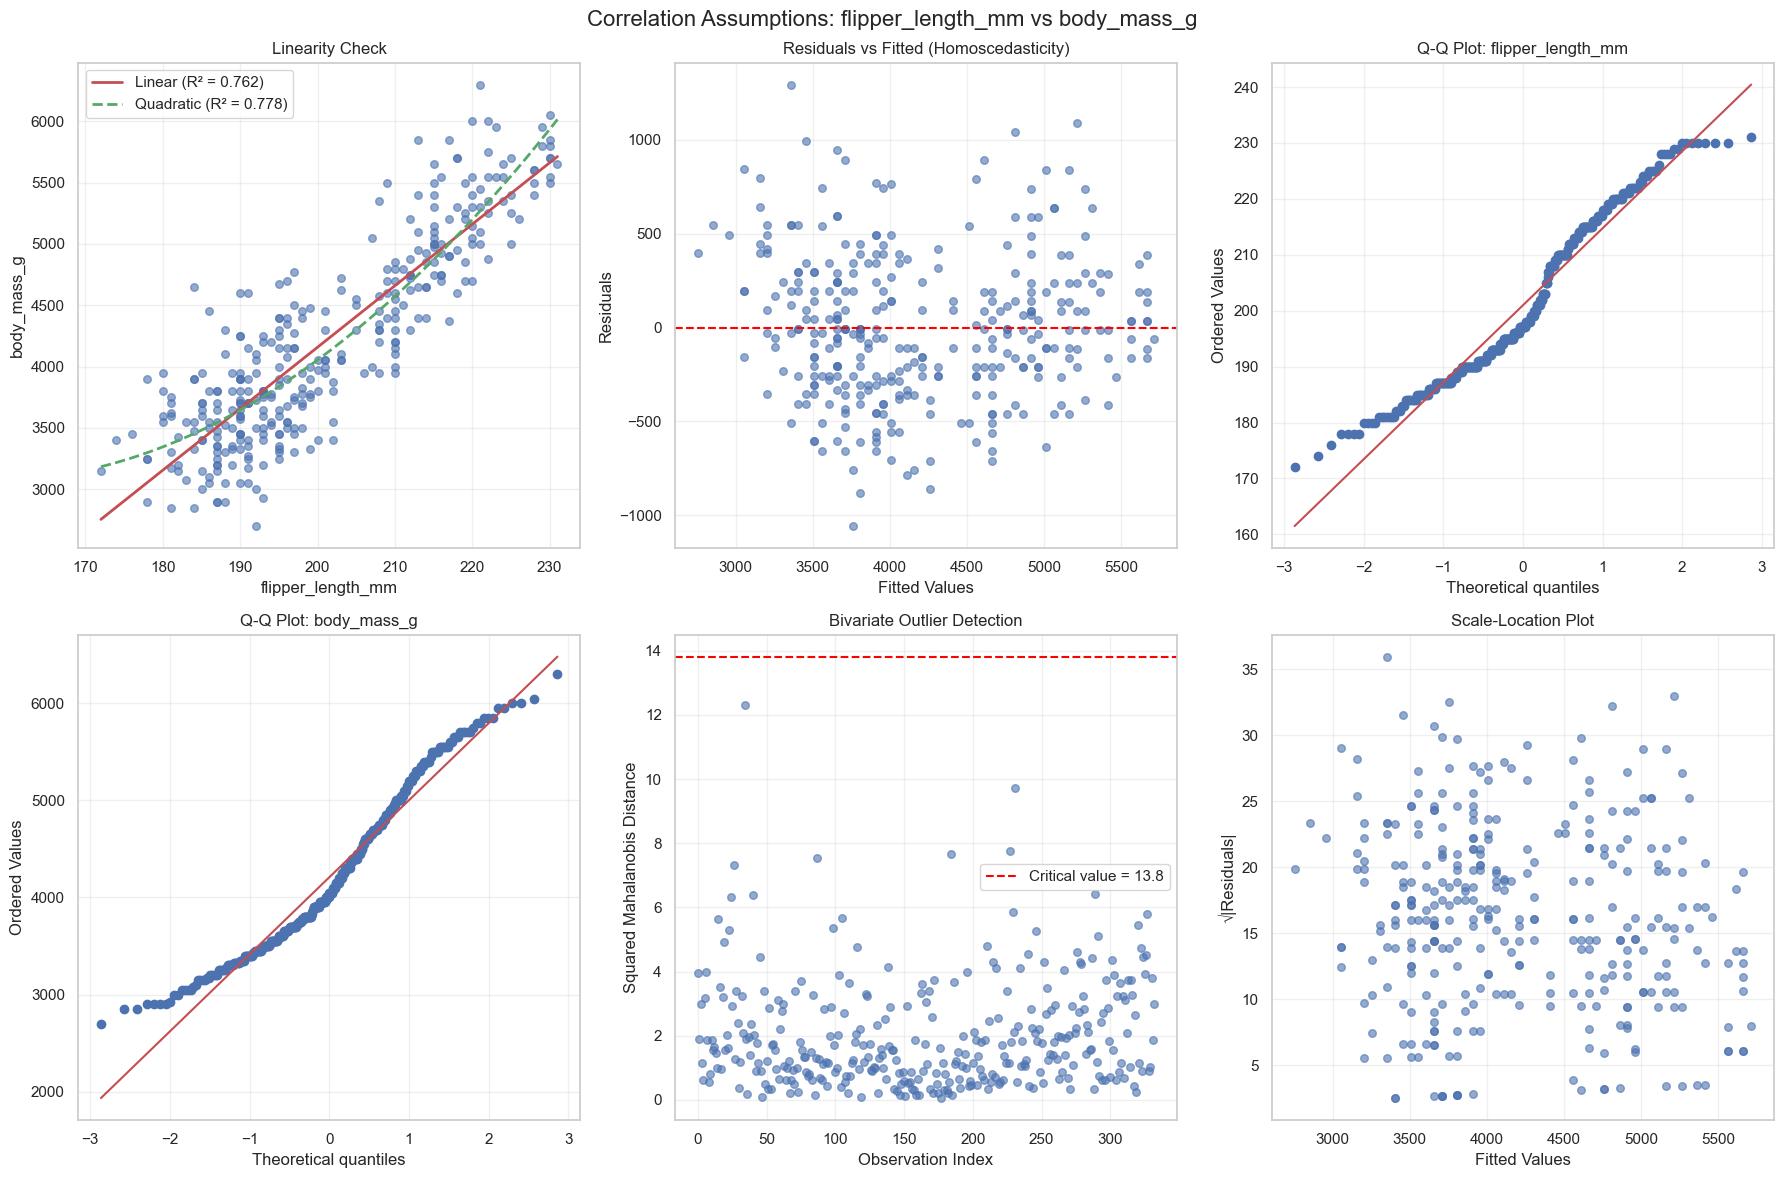


ASSUMPTION CHECK SUMMARY
Assumptions satisfied: 2/5
Recommendation: Consider both Pearson and Spearman correlations

 Analyzing bill_length_mm vs bill_depth_mm

ASSUMPTION CHECKING: bill_length_mm vs bill_depth_mm
Sample size: 333 complete pairs

1. LINEAR RELATIONSHIP
-------------------------
Linear R² = 0.0523
Quadratic R² = 0.1095
R² improvement = 0.0573
Linearity assumption: QUESTIONABLE

2. NORMALITY
---------------
bill_length_mm: W = 0.9743, p = 0.0000 (Non-normal)
bill_depth_mm: W = 0.9733, p = 0.0000 (Non-normal)

3. HOMOSCEDASTICITY
--------------------
Breusch-Pagan-like test:
Correlation |residuals| vs fitted: r = -0.2657, p = 0.0000
Homoscedasticity assumption: VIOLATED

4. OUTLIER DETECTION
--------------------
Univariate outliers (|z| > 3):
  bill_length_mm: 0 (0.0%)
  bill_depth_mm: 0 (0.0%)
Bivariate outliers (Mahalanobis): 0 (0.0%)
Outlier assumption: SATISFIED


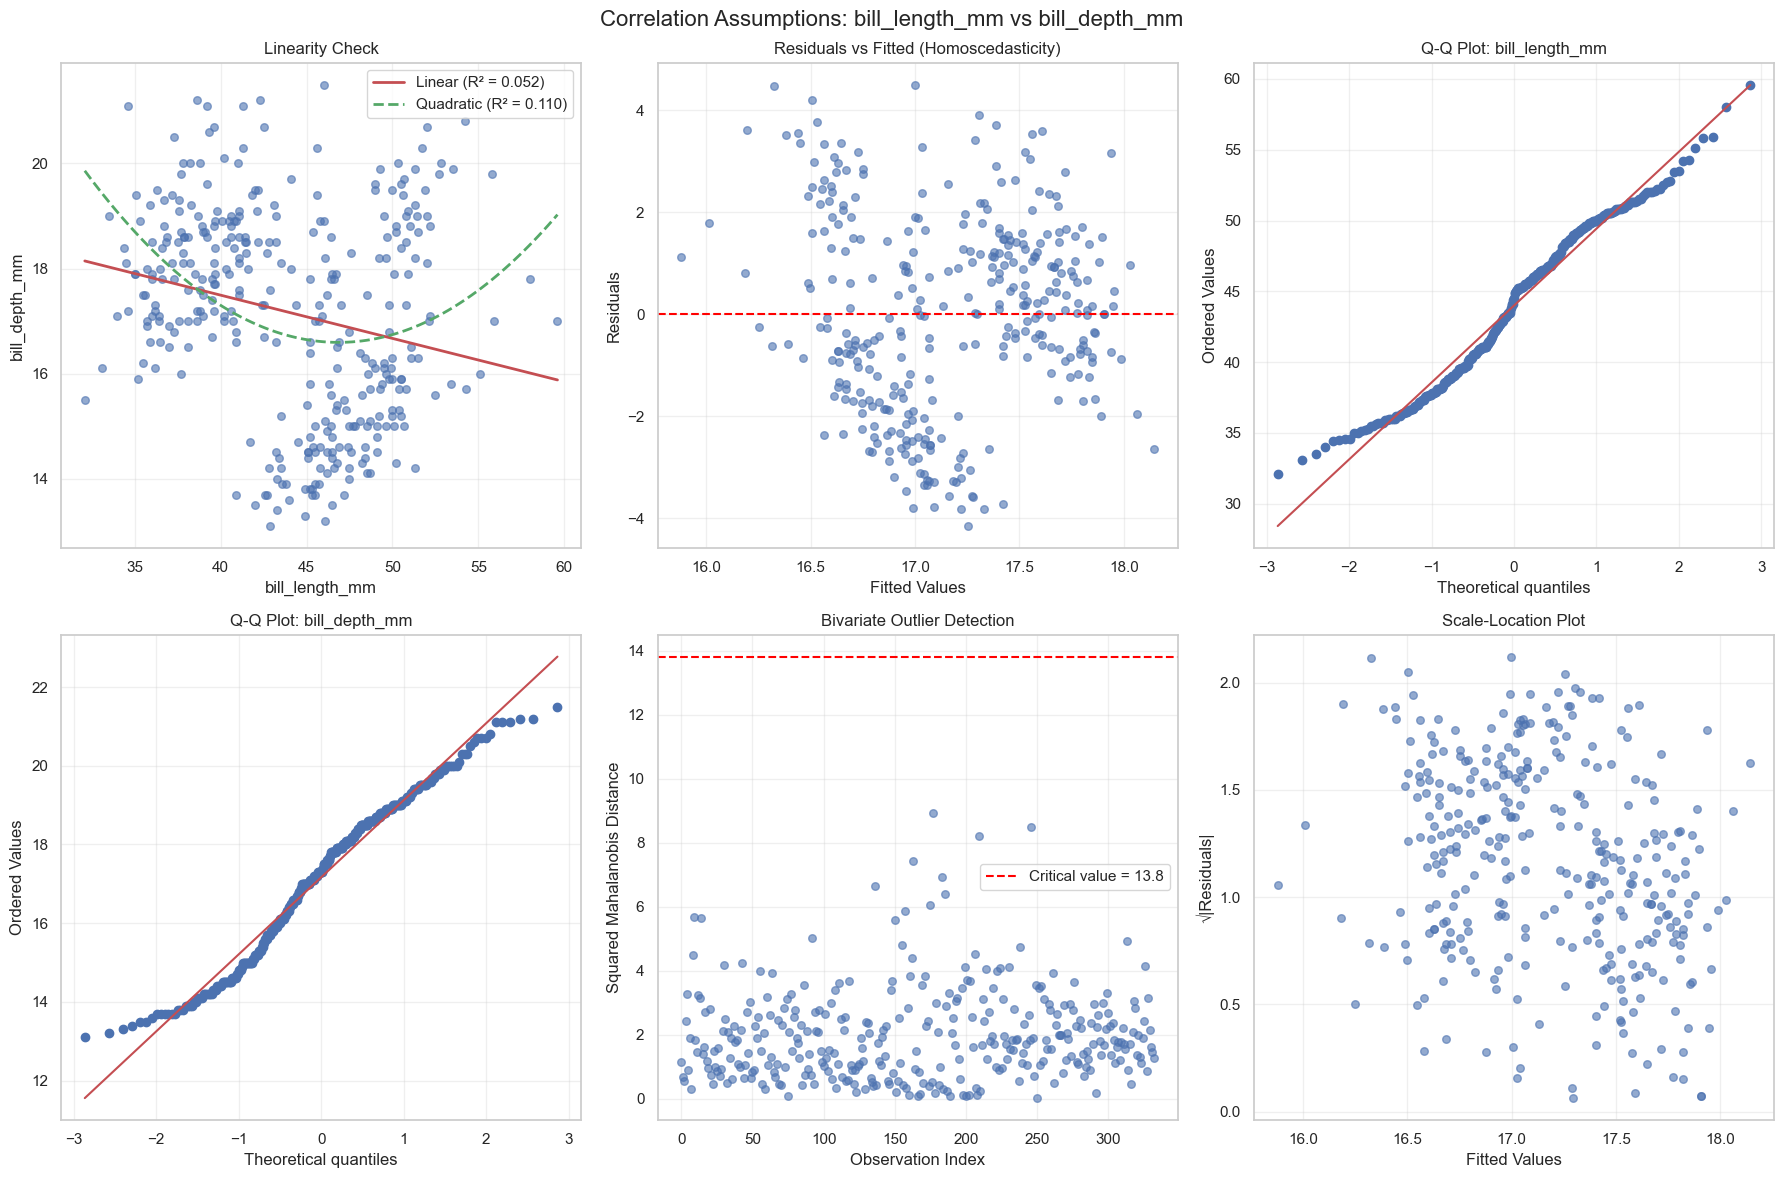


ASSUMPTION CHECK SUMMARY
Assumptions satisfied: 1/5
Recommendation: Spearman correlation recommended

 Analyzing bill_length_mm vs body_mass_g

ASSUMPTION CHECKING: bill_length_mm vs body_mass_g
Sample size: 333 complete pairs

1. LINEAR RELATIONSHIP
-------------------------
Linear R² = 0.3475
Quadratic R² = 0.3604
R² improvement = 0.0130
Linearity assumption: SATISFIED

2. NORMALITY
---------------
bill_length_mm: W = 0.9743, p = 0.0000 (Non-normal)
body_mass_g: W = 0.9580, p = 0.0000 (Non-normal)

3. HOMOSCEDASTICITY
--------------------
Breusch-Pagan-like test:
Correlation |residuals| vs fitted: r = 0.5155, p = 0.0000
Homoscedasticity assumption: VIOLATED

4. OUTLIER DETECTION
--------------------
Univariate outliers (|z| > 3):
  bill_length_mm: 0 (0.0%)
  body_mass_g: 0 (0.0%)
Bivariate outliers (Mahalanobis): 0 (0.0%)
Outlier assumption: SATISFIED


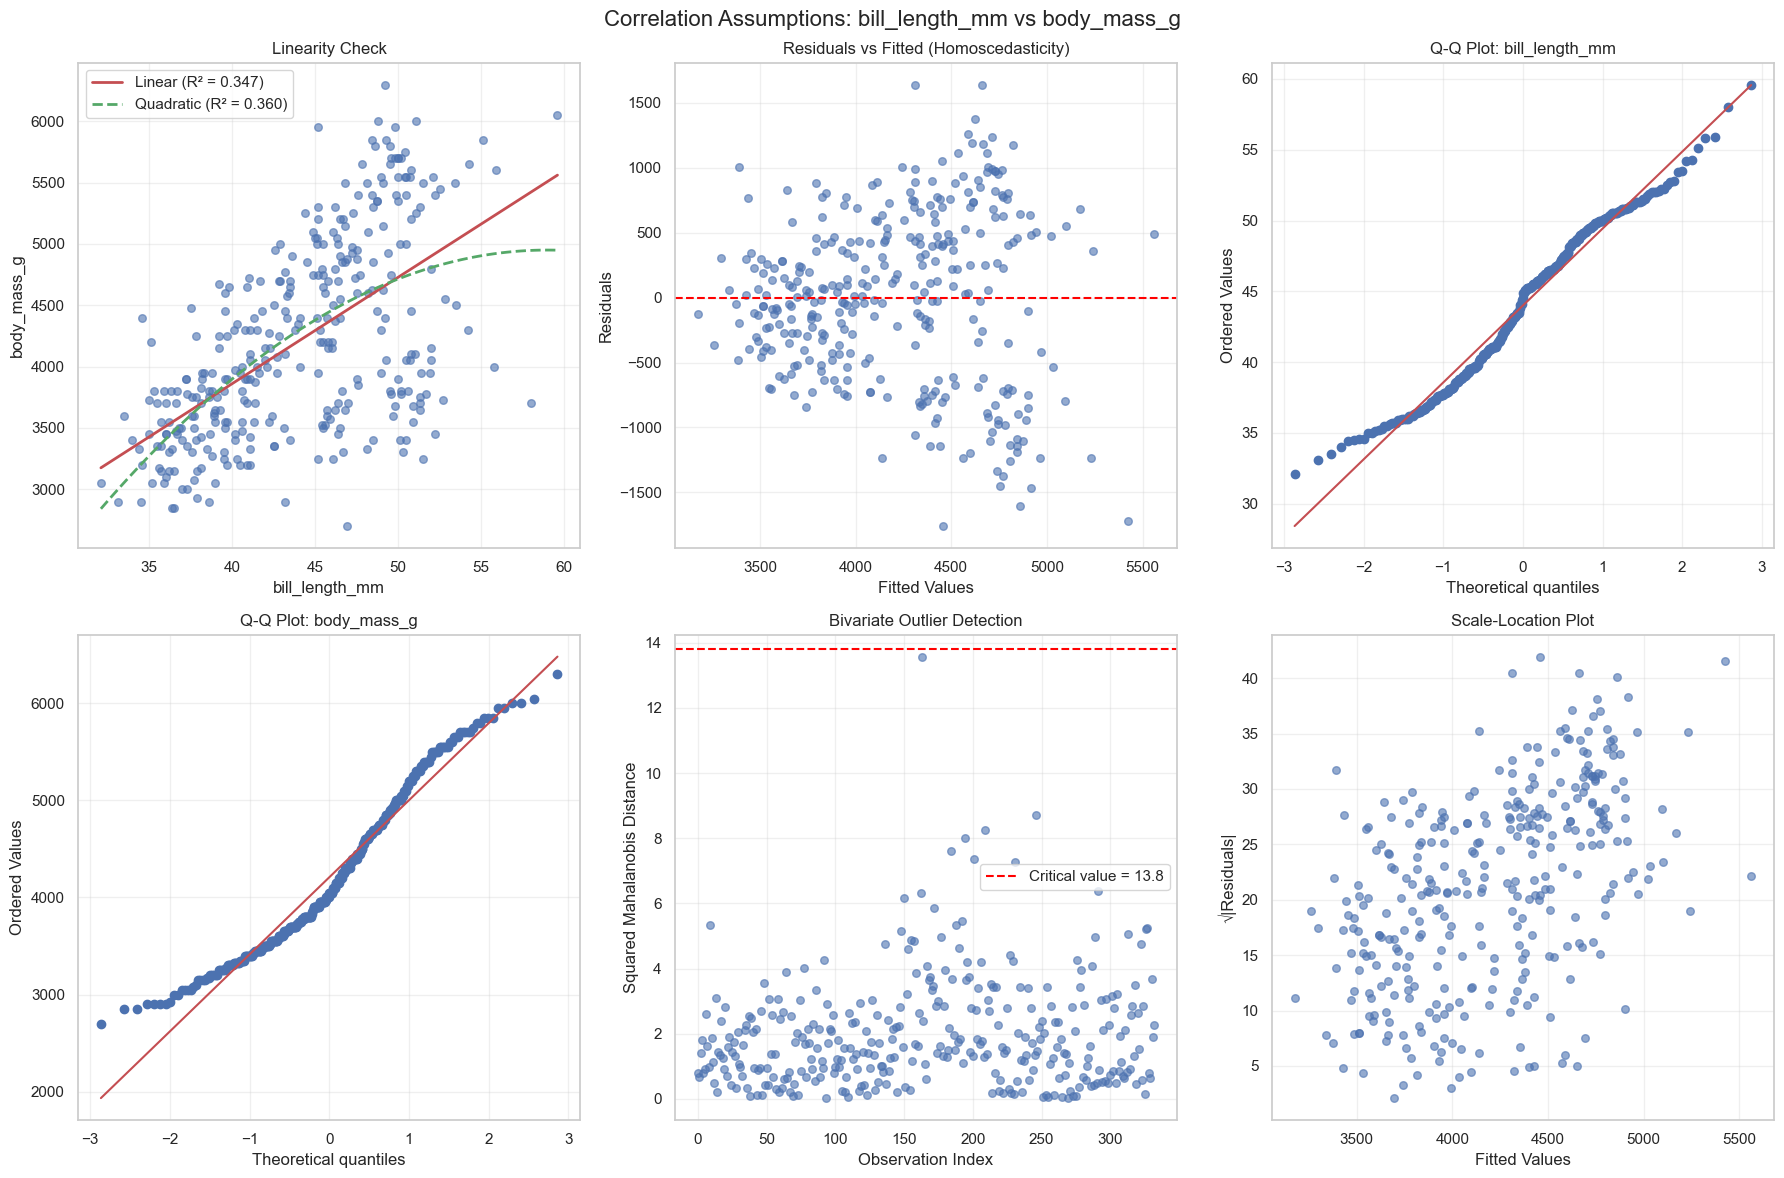


ASSUMPTION CHECK SUMMARY
Assumptions satisfied: 2/5
Recommendation: Consider both Pearson and Spearman correlations

ASSUMPTION CHECK SUMMARY FOR ALL PAIRS

flipper length mm ↔ body mass g:
  Assumptions met: 2/5
  Recommendation: Consider both Pearson and Spearman correlations
  Pearson r = 0.873

bill length mm ↔ bill depth mm:
  Assumptions met: 1/5
  Recommendation: Spearman correlation recommended
  Pearson r = -0.229

bill length mm ↔ body mass g:
  Assumptions met: 2/5
  Recommendation: Consider both Pearson and Spearman correlations
  Pearson r = 0.589

 Step 2: Spearman correlation analysis

SPEARMAN'S RANK CORRELATION ANALYSIS
Spearman's rank correlation (ρ) measures monotonic relationships
It's robust to outliers and doesn't assume normality or linearity

Spearman Correlation Matrix:
------------------------------
                   bill_length_mm  bill_depth_mm  flipper_length_mm  \
bill_length_mm              1.000         -0.214              0.670   
bill_depth_mm       

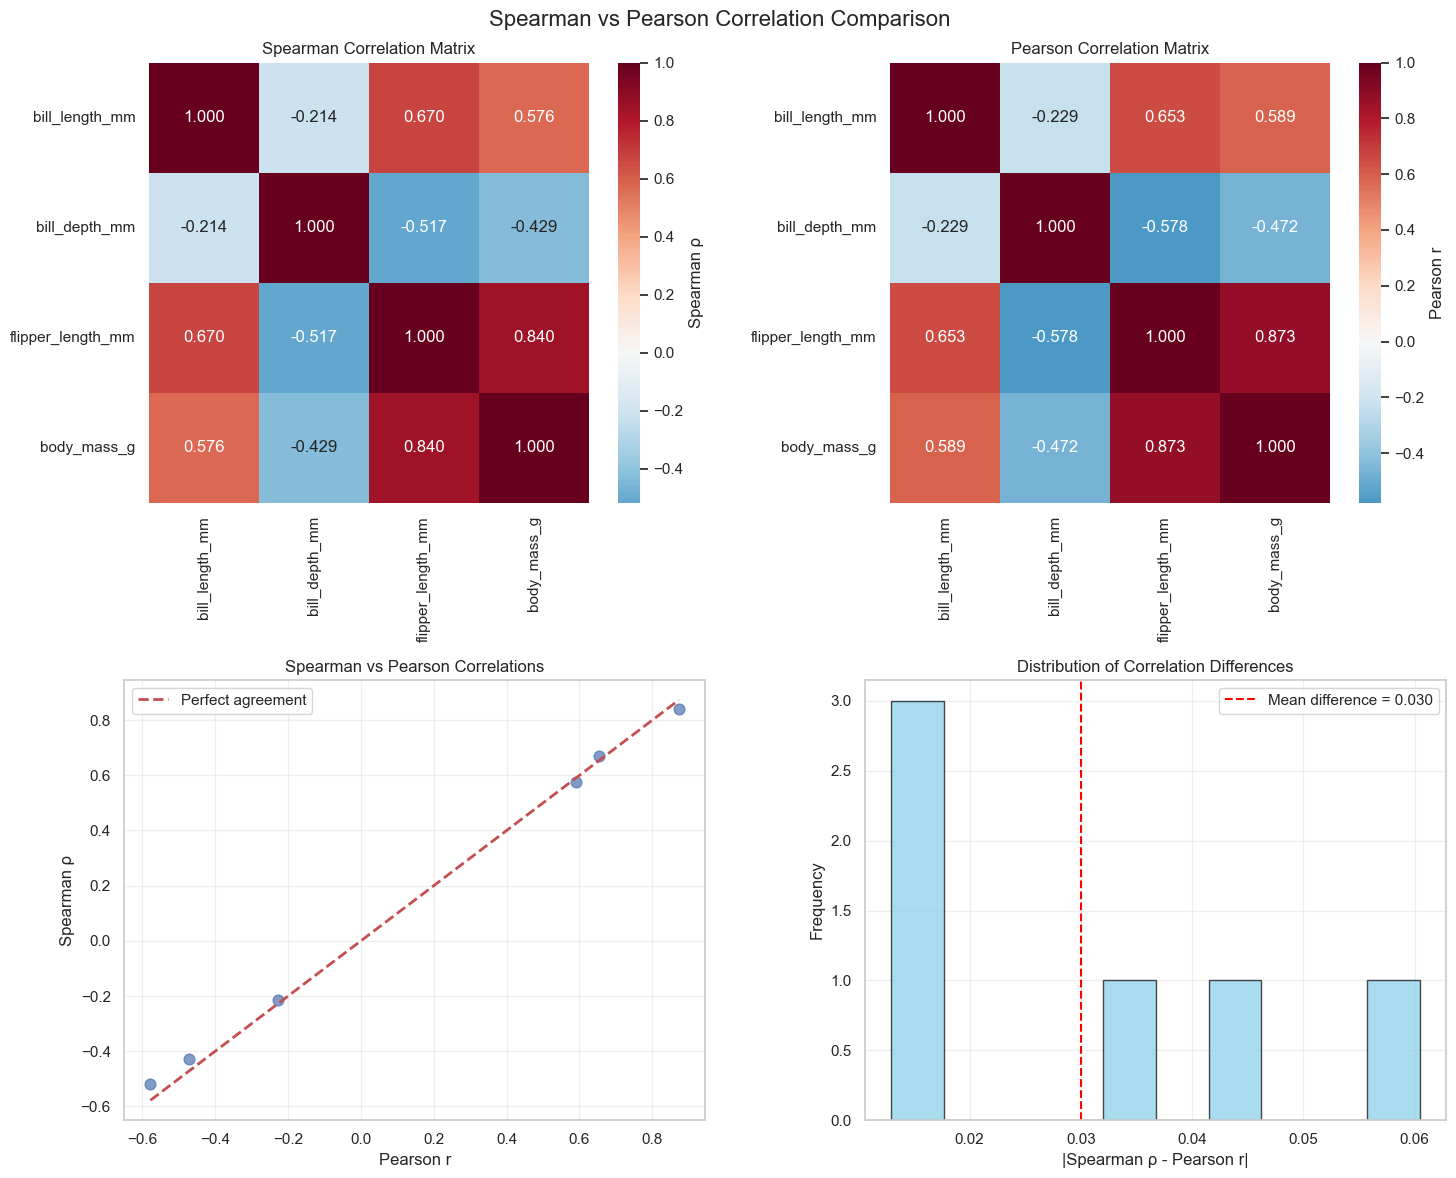

Comparison Summary:
--------------------
Mean absolute difference: 0.030
Maximum difference: 0.060
Number of pairs with |diff| > 0.1: 0
Number of pairs with |diff| > 0.2: 0


In [10]:
def check_correlation_assumptions(data, var1, var2, create_plots=True):
    """
    Assumption checking for Pearson correlation between two variables.
    """
    print(f"\n" + "=" * 60)
    print(f"ASSUMPTION CHECKING: {var1} vs {var2}")
    print("=" * 60)

    # Get clean data for the pair
    clean_data = data[[var1, var2]].dropna()
    x = clean_data[var1]
    y = clean_data[var2]
    n = len(clean_data)

    print(f"Sample size: {n} complete pairs")

    # 1. Linear relationship check
    print(f"\n1. LINEAR RELATIONSHIP")
    print("-" * 25)

    # Calculate Pearson correlation
    r_pearson, p_pearson = pearsonr(x, y)

    # Fit polynomial models to test for non-linearity
    #Note: Remember that R-squared indicates how well the model fits the data
    # Linear model (degree 1)
    linear_coef = np.polyfit(x, y, 1)
    linear_pred = np.polyval(linear_coef, x)
    linear_r2 = 1 - (np.sum((y - linear_pred) ** 2) / np.sum((y - np.mean(y)) ** 2))

    # Quadratic model (degree 2)
    quad_coef = np.polyfit(x, y, 2)
    quad_pred = np.polyval(quad_coef, x)
    quad_r2 = 1 - (np.sum((y - quad_pred) ** 2) / np.sum((y - np.mean(y)) ** 2))

    # Test for non-linearity
    r2_improvement = quad_r2 - linear_r2
    linearity_ok = r2_improvement < 0.05  # Arbitrary threshold

    print(f"Linear R² = {linear_r2:.4f}")
    print(f"Quadratic R² = {quad_r2:.4f}")
    print(f"R² improvement = {r2_improvement:.4f}")
    print(f"Linearity assumption: {'SATISFIED' if linearity_ok else 'QUESTIONABLE'}")

    # 2. Normality check
    print(f"\n2. NORMALITY")
    print("-" * 15)

    # Shapiro-Wilk tests (use sample if too large)
    x_sample = x.sample(min(5000, len(x)), random_state=42) if len(x) > 5000 else x
    y_sample = y.sample(min(5000, len(y)), random_state=42) if len(y) > 5000 else y

    shapiro_x = stats.shapiro(x_sample)
    shapiro_y = stats.shapiro(y_sample)

    normality_x = shapiro_x.pvalue > 0.05
    normality_y = shapiro_y.pvalue > 0.05

    print(f"{var1}: W = {shapiro_x.statistic:.4f}, p = {shapiro_x.pvalue:.4f} ({'Normal' if normality_x else 'Non-normal'})")
    print(f"{var2}: W = {shapiro_y.statistic:.4f}, p = {shapiro_y.pvalue:.4f} ({'Normal' if normality_y else 'Non-normal'})")

    # 3. Homoscedasticity check
    print(f"\n3. HOMOSCEDASTICITY")
    print("-" * 20)

    # Calculate residuals from linear regression
    residuals = y - linear_pred

    # Breusch-Pagan test for heteroscedasticity
    # Simple version: correlation between |residuals| and fitted values
    abs_residuals = np.abs(residuals)
    fitted_values = linear_pred

    hetero_corr, hetero_p = pearsonr(fitted_values, abs_residuals)
    homoscedasticity_ok = hetero_p > 0.05

    print(f"Breusch-Pagan-like test:")
    print(f"Correlation |residuals| vs fitted: r = {hetero_corr:.4f}, p = {hetero_p:.4f}")
    print(f"Homoscedasticity assumption: {'SATISFIED' if homoscedasticity_ok else 'VIOLATED'}")

    # 4. Outlier detection
    print(f"\n4. OUTLIER DETECTION")
    print("-" * 20)

    # Z-score method for univariate outliers
    #Note: Remember that Z-score indicates how many standard deviations a data point is from the mean of a distribution
    z_scores_x = np.abs(stats.zscore(x))
    z_scores_y = np.abs(stats.zscore(y))

    outliers_x = np.sum(z_scores_x > 3)
    outliers_y = np.sum(z_scores_y > 3)

    # Bivariate outliers using Mahalanobis distance
    data_array = np.column_stack([x, y])    # Combine x and y into a 2D array
    mean_vec = np.mean(data_array, axis=0)   # Calculate mean of x and mean of y
    cov_matrix = np.cov(data_array.T)    # Calculate covariance matrix

    try:
        inv_cov = np.linalg.inv(cov_matrix)   # Invert the covariance matrix
        mahal_dist = []
        for i in range(len(data_array)):
            diff = data_array[i] - mean_vec   # How far this point is from the center
            mahal_dist.append(np.sqrt(diff.T @ inv_cov @ diff))  # Mahalanobis distance formula

        mahal_dist = np.array(mahal_dist)
        # Chi-square critical value for 2 variables at 99.9% confidence
        chi2_critical = stats.chi2.ppf(0.999, df=2)    # Get chi-square threshold for 99.9% confidence
        bivariate_outliers = np.sum(mahal_dist**2 > chi2_critical)  # Count outliers

    except np.linalg.LinAlgError:
        bivariate_outliers = 0
        mahal_dist = np.zeros(len(data_array))

    total_outliers = max(outliers_x, outliers_y, bivariate_outliers)
    outliers_ok = total_outliers < (0.05 * n)  # Less than 5% outliers

    print(f"Univariate outliers (|z| > 3):")
    print(f"  {var1}: {outliers_x} ({outliers_x/n*100:.1f}%)")
    print(f"  {var2}: {outliers_y} ({outliers_y/n*100:.1f}%)")
    print(f"Bivariate outliers (Mahalanobis): {bivariate_outliers} ({bivariate_outliers/n*100:.1f}%)")
    print(f"Outlier assumption: {'SATISFIED' if outliers_ok else 'ATTENTION NEEDED'}")

    # Create diagnostic plots if requested
    if create_plots:
        fig, axes = plt.subplots(2, 3, figsize=(18, 12))
        fig.suptitle(f'Correlation Assumptions: {var1} vs {var2}', fontsize=16)

        # Plot 1: Scatter plot with linear and quadratic fits
        axes[0, 0].scatter(x, y, alpha=0.6, s=30)

        # Linear fit
        x_line = np.linspace(x.min(), x.max(), 100)
        y_linear = np.polyval(linear_coef, x_line)
        y_quad = np.polyval(quad_coef, x_line)

        axes[0, 0].plot(x_line, y_linear, 'r-', linewidth=2, label=f'Linear (R² = {linear_r2:.3f})')
        axes[0, 0].plot(x_line, y_quad, 'g--', linewidth=2, label=f'Quadratic (R² = {quad_r2:.3f})')

        axes[0, 0].set_xlabel(var1)
        axes[0, 0].set_ylabel(var2)
        axes[0, 0].set_title('Linearity Check')
        axes[0, 0].legend()
        axes[0, 0].grid(True, alpha=0.3)

        # Plot 2: Residuals vs Fitted (homoscedasticity)
        axes[0, 1].scatter(fitted_values, residuals, alpha=0.6, s=30)
        axes[0, 1].axhline(y=0, color='red', linestyle='--')
        axes[0, 1].set_xlabel('Fitted Values')
        axes[0, 1].set_ylabel('Residuals')
        axes[0, 1].set_title('Residuals vs Fitted (Homoscedasticity)')
        axes[0, 1].grid(True, alpha=0.3)

        # Plot 3: Q-Q plot for X variable
        stats.probplot(x, dist="norm", plot=axes[0, 2])
        axes[0, 2].set_title(f'Q-Q Plot: {var1}')
        axes[0, 2].grid(True, alpha=0.3)

        # Plot 4: Q-Q plot for Y variable
        stats.probplot(y, dist="norm", plot=axes[1, 0])
        axes[1, 0].set_title(f'Q-Q Plot: {var2}')
        axes[1, 0].grid(True, alpha=0.3)

        # Plot 5: Outlier detection (Mahalanobis distance)
        if len(mahal_dist) > 0:
            axes[1, 1].scatter(range(len(mahal_dist)), mahal_dist**2, alpha=0.6, s=30)
            axes[1, 1].axhline(y=chi2_critical, color='red', linestyle='--',
                              label=f'Critical value = {chi2_critical:.1f}')
            axes[1, 1].set_xlabel('Observation Index')
            axes[1, 1].set_ylabel('Squared Mahalanobis Distance')
            axes[1, 1].set_title('Bivariate Outlier Detection')
            axes[1, 1].legend()
        axes[1, 1].grid(True, alpha=0.3)

        # Plot 6: Scale-Location plot
        sqrt_abs_residuals = np.sqrt(np.abs(residuals))
        axes[1, 2].scatter(fitted_values, sqrt_abs_residuals, alpha=0.6, s=30)
        axes[1, 2].set_xlabel('Fitted Values')
        axes[1, 2].set_ylabel('√|Residuals|')
        axes[1, 2].set_title('Scale-Location Plot')
        axes[1, 2].grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

    # Summary
    assumptions_met = sum([linearity_ok, normality_x, normality_y, homoscedasticity_ok, outliers_ok])
    total_assumptions = 5

    print(f"\n" + "=" * 50)
    print("ASSUMPTION CHECK SUMMARY")
    print("=" * 50)
    print(f"Assumptions satisfied: {assumptions_met}/{total_assumptions}")

    if assumptions_met >= 4:
        recommendation = "Pearson correlation is appropriate"
    elif assumptions_met >= 2:
        recommendation = "Consider both Pearson and Spearman correlations"
    else:
        recommendation = "Spearman correlation recommended"

    print(f"Recommendation: {recommendation}")

    return {
        'linearity': linearity_ok,
        'normality_x': normality_x,
        'normality_y': normality_y,
        'homoscedasticity': homoscedasticity_ok,
        'outliers_ok': outliers_ok,
        'assumptions_met': assumptions_met,
        'recommendation': recommendation,
        'pearson_r': r_pearson,
        'sample_size': n,
        'outlier_counts': {
            'univariate_x': outliers_x,
            'univariate_y': outliers_y,
            'bivariate': bivariate_outliers
        }
    }


def perform_spearman_correlation(data, continuous_vars):
    """
    Perform Spearman's rank correlation analysis as a non-parametric alternative.
    """
    print(f"\n" + "=" * 70)
    print("SPEARMAN'S RANK CORRELATION ANALYSIS")
    print("=" * 70)

    print("Spearman's rank correlation (ρ) measures monotonic relationships")
    print("It's robust to outliers and doesn't assume normality or linearity")
    print()

    # Calculate Spearman correlation matrix - using pandas .corr function - all pairs results simultaneously
    # Note: The .corr(method='spearman' method automatically converts data to ranks
    spearman_matrix = data[continuous_vars].corr(method='spearman')

    print("Spearman Correlation Matrix:")
    print("-" * 30)
    print(spearman_matrix.round(3))

    # Compare with Pearson correlations
    pearson_matrix = data[continuous_vars].corr(method='pearson')

# Just so we can print p-values, let us do this individually, for each pair of variables at a time
# using the scipy.stats functions, which returns the p-values
    print(f"\nSpearman vs Pearson Correlations:")
    print("-" * 35)

    spearman_results = []

    for i in range(len(continuous_vars)):
        for j in range(i+1, len(continuous_vars)):
            var1 = continuous_vars[i]
            var2 = continuous_vars[j]

            # Get aligned data first, then calculate correlations
            clean_data = data[[var1, var2]].dropna()
            x = clean_data[var1]
            y = clean_data[var2]

            # Spearman correlation (using function from scipy.stats)
            rho, p_spearman = spearmanr(x, y)

            # Pearson correlation for comparison (using function from scipy.stats)
            r_pearson, p_pearson = pearsonr(x, y)

            # Calculate difference
            diff = abs(rho - r_pearson)

            spearman_results.append({
                'var1': var1,
                'var2': var2,
                'spearman_rho': rho,
                'spearman_p': p_spearman,
                'pearson_r': r_pearson,
                'pearson_p': p_pearson,
                'difference': diff,
                'sample_size': len(clean_data)
            })

            # Interpret difference
            if diff < 0.1:
                agreement = "High agreement"
            elif diff < 0.2:
                agreement = "Moderate agreement"
            else:
                agreement = "Poor agreement"

            print(f"{var1} ↔ {var2}:")
            print(f"  Spearman ρ = {rho:>7.3f} (p = {p_spearman:>6.4f})")
            print(f"  Pearson  r = {r_pearson:>7.3f} (p = {p_pearson:>6.4f})")
            print(f"  Difference = {diff:>7.3f} ({agreement})")
            print()

    # Create comparison visualization
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    fig.suptitle('Spearman vs Pearson Correlation Comparison', fontsize=16)

    # Plot 1: Spearman correlation heatmap
    #mask = np.triu(np.ones_like(spearman_matrix, dtype=bool))
    sns.heatmap(spearman_matrix,
                #mask=mask,
                annot=True, cmap='RdBu_r', center=0,
                square=True, fmt='.3f', ax=axes[0, 0],
                cbar_kws={'label': 'Spearman ρ'})
    axes[0, 0].set_title('Spearman Correlation Matrix')

    # Plot 2: Pearson correlation heatmap
    sns.heatmap(pearson_matrix,
                #mask=mask,
                annot=True, cmap='RdBu_r', center=0,
                square=True, fmt='.3f', ax=axes[0, 1],
                cbar_kws={'label': 'Pearson r'})
    axes[0, 1].set_title('Pearson Correlation Matrix')

    # Plot 3: Spearman vs Pearson scatter plot
    spearman_values = []
    pearson_values = []

    for result in spearman_results:
        spearman_values.append(result['spearman_rho'])
        pearson_values.append(result['pearson_r'])

    axes[1, 0].scatter(pearson_values, spearman_values, alpha=0.7, s=60)

    # Add diagonal line (perfect agreement)
    min_val = min(min(spearman_values), min(pearson_values))
    max_val = max(max(spearman_values), max(pearson_values))
    axes[1, 0].plot([min_val, max_val], [min_val, max_val], 'r--',
                   linewidth=2, label='Perfect agreement')

    axes[1, 0].set_xlabel('Pearson r')
    axes[1, 0].set_ylabel('Spearman ρ')
    axes[1, 0].set_title('Spearman vs Pearson Correlations')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)

    # Plot 4: Difference magnitude histogram
    differences = [result['difference'] for result in spearman_results]
    axes[1, 1].hist(differences, bins=10, alpha=0.7, color='skyblue', edgecolor='black')
    axes[1, 1].set_xlabel('|Spearman ρ - Pearson r|')
    axes[1, 1].set_ylabel('Frequency')
    axes[1, 1].set_title('Distribution of Correlation Differences')
    axes[1, 1].grid(True, alpha=0.3)

    # Add statistics
    mean_diff = np.mean(differences)
    max_diff = np.max(differences)
    axes[1, 1].axvline(mean_diff, color='red', linestyle='--',
                      label=f'Mean difference = {mean_diff:.3f}')
    axes[1, 1].legend()

    plt.tight_layout()
    plt.show()

    # Summary statistics
    print(f"Comparison Summary:")
    print("-" * 20)
    print(f"Mean absolute difference: {mean_diff:.3f}")
    print(f"Maximum difference: {max_diff:.3f}")
    print(f"Number of pairs with |diff| > 0.1: {sum(1 for d in differences if d > 0.1)}")
    print(f"Number of pairs with |diff| > 0.2: {sum(1 for d in differences if d > 0.2)}")

    return {
        'spearman_matrix': spearman_matrix,
        'pairwise_results': spearman_results,
        'comparison_stats': {
            'mean_difference': mean_diff,
            'max_difference': max_diff,
            'differences': differences
        }
    }


def analyze_penguin_correlations_comprehensive(data, continuous_vars):
    """
    Comprehensive correlation analysis of penguin data with both methods.
    """
    print(f"\n" + "=" * 70)
    print("COMPREHENSIVE PENGUIN CORRELATION ANALYSIS")
    print("=" * 70)

    # Check assumptions for key variable pairs
    key_pairs = [
        ('flipper_length_mm', 'body_mass_g'),
        ('bill_length_mm', 'bill_depth_mm'),
        ('bill_length_mm', 'body_mass_g')
    ]

    assumption_results = {}

    for var1, var2 in key_pairs:
        print(f"\n Analyzing {var1} vs {var2}")
        assumption_results[f"{var1}_{var2}"] = check_correlation_assumptions(
            data, var1, var2, create_plots=True
        )

    # Summary of assumption checks
    print(f"\n" + "=" * 50)
    print("ASSUMPTION CHECK SUMMARY FOR ALL PAIRS")
    print("=" * 50)

    for pair_name, results in assumption_results.items():
        # FIXED: More robust string splitting
        parts = pair_name.split('_')
        # Reconstruct variable names properly
        if len(parts) >= 4:  # e.g., "bill_length_mm_body_mass_g"
            var1 = '_'.join(parts[:-3])  # Everything except last 3 parts
            var2 = '_'.join(parts[-3:])  # Last 3 parts
        else:
            var1, var2 = pair_name.split('_', 1)

        var1_clean = var1.replace('_', ' ')
        var2_clean = var2.replace('_', ' ')

        print(f"\n{var1_clean} ↔ {var2_clean}:")
        print(f"  Assumptions met: {results['assumptions_met']}/5")
        print(f"  Recommendation: {results['recommendation']}")
        print(f"  Pearson r = {results['pearson_r']:.3f}")

    return assumption_results


# Execute the analysis
print("\n EXECUTING ASSUMPTION CHECKING AND SPEARMAN ANALYSIS")
print("=" * 60)

# Step 1: Comprehensive assumption checking
print("\n Step 1: Checking correlation assumptions for key variable pairs")
penguin_assumptions = analyze_penguin_correlations_comprehensive(penguins_clean, continuous_vars)

# Step 2: Spearman correlation analysis
print("\n Step 2: Spearman correlation analysis")
spearman_results = perform_spearman_correlation(penguins_clean, continuous_vars)
     